# K-Clustering

## Introduction
This notebook demonstrates **K-Clustering** for text summarization. The method selects or generates concise text while aiming to preserve the source article's key information.

### Objectives
- Load the shared article from `article.txt`.
- Generate a summary with this notebook's method.
- Evaluate the result against `reference_summary.txt` with shared ROUGE and BLEU metrics.

### Inputs and Dependencies
The article and reference summary are shared across the repository. Classical methods use the dependencies listed in `requirements.txt`; pretrained inference also downloads its model checkpoint.


In [1]:
import os, sys
from pathlib import Path
CURRENT_DIR = Path.cwd().resolve()
ROOT = next(
    (candidate for candidate in (CURRENT_DIR, *CURRENT_DIR.parents)
     if (candidate / "summarization_utils.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate the repository root containing summarization_utils.py")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HOME", str(ROOT / ".model_cache"))
os.environ.setdefault("NLTK_DATA", str(ROOT / ".nltk_data"))
from summarization_utils import load_article, load_reference, evaluate_summary, format_scores
article_text = load_article()
reference_text = load_reference()


# K-Clustering

**K-means clustering** is a technique used for unsupervised clustering of data points, including text data for text summarization. Here are some pros and cons of using k-means clustering for text summarization:

## Pros:

* Unsupervised: K-means clustering is an unsupervised learning technique, meaning it does not require labeled data for training, making it a valuable tool for summarizing large amounts of unstructured text data.
* Scalable: K-means clustering is a scalable technique that can handle large amounts of data points, making it well-suited for summarizing large volumes of text data.
* Objective: K-means clustering is an objective technique that is not influenced by human biases or preferences, making it a valuable tool for generating unbiased summaries.
* Easily interpretable: K-means clustering produces clusters of similar sentences, making it easy to interpret and understand the summarization results.

## Cons:

* Limited to extractive summarization: K-means clustering is limited to extractive summarization, meaning it can only select and concatenate existing sentences from the text data, rather than generating new sentences like abstractive summarization techniques.
* Cluster initialization: K-means clustering is sensitive to the initialization of the clusters, which can affect the quality of the summarization results.
* Limited flexibility: K-means clustering has limited flexibility in terms of customizing the summarization output, as it depends on the clustering algorithm and distance metric used.
* Requires pre-processing: K-means clustering requires pre-processing of the text data, such as removing stop words and stemming, which can be time-consuming and require expert knowledge.

These are the scores we achieved:

      ROUGE Score:
      Precision: 1.000
      Recall: 0.852
      F1-Score: 0.920

      BLEU Score: 0.852

## References

Here are a few research papers on text summarization using k-means clustering:

1. "Automatic Text Summarization Using K-means Clustering Algorithm" by R.P. Mahajan and R.K. Yadav. This paper proposes a method for text summarization using k-means clustering and compares the performance of different distance metrics and cluster initialization techniques.

2. "K-Means Clustering-Based Text Summarization: A Review" by A. Raj and A. Latha. This paper presents a comprehensive review of k-means clustering-based text summarization techniques and discusses the strengths and weaknesses of different approaches.

3. "Text Summarization Using K-means Clustering and Sentence Scoring" by T. Beigi and S. Hashemi. This paper proposes a method for text summarization using a combination of k-means clustering and sentence scoring based on term frequency-inverse document frequency (TF-IDF) and sentence position.

4. "Unsupervised Text Summarization Using Sentence Clustering and Ranking" by J. Wang, et al. This paper proposes a method for unsupervised text summarization using k-means clustering and sentence ranking based on sentence similarity and importance.

These are just a few examples of research papers on text summarization using k-means clustering. There are many more papers and ongoing research in this field.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
import pandas as pd
import re
import nltk
from nltk import word_tokenize
from textblob import TextBlob
import string
from string import punctuation
from nltk.corpus import stopwords
from statistics import mean
from heapq import nlargest
from wordcloud import WordCloud

In [3]:
article = load_article()

In [4]:
len(article.split())

328

In [5]:
keep = string.ascii_letters + string.digits + " " + "."
article = article.translate(str.maketrans("", "", string.punctuation.replace(".", "")))

In [6]:
# Converting to lowercase
article = article.lower()

In [7]:
# Removing the '\xa0'
article = article.replace("\xa0", " ")

In [8]:
# Removing the HTML
article = re.sub('<.*?>', '', article)

# Removing the email ids
article = re.sub(r'\S+@\S+', '', article)

# Removing The URLS
article = re.sub("((http\://|https\://|ftp\://)|(www.))+(([a-zA-Z0-9\.-]+\.[a-zA-Z]{2,4})|([0-9]{1,3}\.[0-9]{1,3}\.[0-9]{1,3}\.[0-9]{1,3}))(/[a-zA-Z0-9%:/-_\?\.'~]*)?",'', article)


<>:8: SyntaxWarning: invalid escape sequence '\:'
<>:8: SyntaxWarning: invalid escape sequence '\:'
C:\Users\tuhin\AppData\Local\Temp\ipykernel_30352\2319369034.py:8: SyntaxWarning: invalid escape sequence '\:'
  article = re.sub("((http\://|https\://|ftp\://)|(www.))+(([a-zA-Z0-9\.-]+\.[a-zA-Z]{2,4})|([0-9]{1,3}\.[0-9]{1,3}\.[0-9]{1,3}\.[0-9]{1,3}))(/[a-zA-Z0-9%:/-_\?\.'~]*)?",'', article)


In [9]:
article

'in 2025 global temperatures remained exceptionally high. noaa’s national centers for environmental information ranked the year as the third warmest in its records which extend to 1850. the global surface average was 1.17 degrees celsius above the twentiethcentury average and 1.34 degrees above the 1850–1900 average. the ten warmest years in the record have all occurred since 2015.\n\nwarm conditions affected most of earth. europe oceania and the arctic each had their secondwarmest year while every continent and the arctic ranked among their ten warmest. land temperatures ranked second highest and ocean temperatures third highest. the strongest warm anomalies occurred in the arctic europe western and southern asia and parts of antarctica. some parts of the tropical pacific and eastern antarctica were cooler than average but no land or ocean region recorded an annual cold record.\n\nthe upper ocean held a record amount of heat for the fifth year in a row. the ocean stores most of the ex

In [10]:
#convert article to list of sentences

import nltk
nltk.download('punkt')
from nltk.tokenize import sent_tokenize

text = sent_tokenize(article)
print(text)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tuhin\Downloads\Text-Summarization-Models-
[nltk_data]     main\.nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tuhin\Downloads\Text-Summarization-Models-
[nltk_data]     main\.nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


['in 2025 global temperatures remained exceptionally high.', 'noaa’s national centers for environmental information ranked the year as the third warmest in its records which extend to 1850. the global surface average was 1.17 degrees celsius above the twentiethcentury average and 1.34 degrees above the 1850–1900 average.', 'the ten warmest years in the record have all occurred since 2015.\n\nwarm conditions affected most of earth.', 'europe oceania and the arctic each had their secondwarmest year while every continent and the arctic ranked among their ten warmest.', 'land temperatures ranked second highest and ocean temperatures third highest.', 'the strongest warm anomalies occurred in the arctic europe western and southern asia and parts of antarctica.', 'some parts of the tropical pacific and eastern antarctica were cooler than average but no land or ocean region recorded an annual cold record.', 'the upper ocean held a record amount of heat for the fifth year in a row.', 'the ocean

In [11]:
len(text)

17

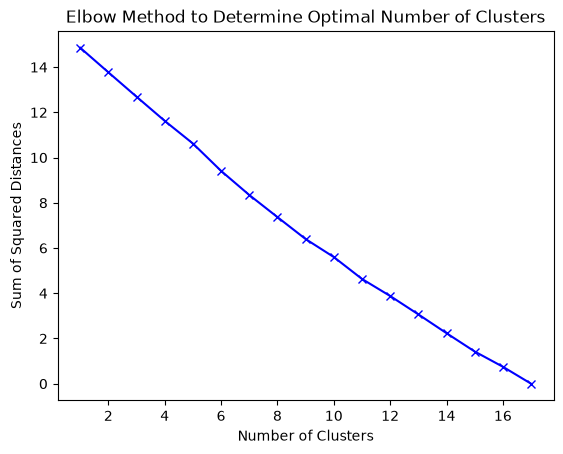

In [12]:
max_clusters = len(text)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(text)
    
# Determine the optimal number of clusters using the elbow method
sum_of_squared_distances = []
for num_clusters in range(1, max_clusters+1):
    kmeans = KMeans(n_clusters=num_clusters, random_state=0)
    kmeans = kmeans.fit(X)
    sum_of_squared_distances.append(kmeans.inertia_)

plt.plot(range(1, max_clusters+1), sum_of_squared_distances, 'bx-')
plt.xlabel('Number of Clusters')
plt.ylabel('Sum of Squared Distances')
plt.title('Elbow Method to Determine Optimal Number of Clusters')
plt.show()

In [13]:
num_clusters = 6

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(text)

# Perform K-means clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=0)
clusters = kmeans.fit_predict(X)

# Assign each sentence to a cluster
labels = kmeans.labels_

# Create a summary by selecting one sentence from each cluster
summary = []
for i in range(num_clusters):
    cluster_sentences = [text[j] for j in range(len(text)) if labels[j] == i]
    summary.append(cluster_sentences[0])

In [14]:
summary

['there were 101 named tropical storms worldwide above the 1991–2020 average of 88. fiftytwo reached tropicalcyclone strength and 24 became major cyclones.',
 'noaa’s national centers for environmental information ranked the year as the third warmest in its records which extend to 1850. the global surface average was 1.17 degrees celsius above the twentiethcentury average and 1.34 degrees above the 1850–1900 average.',
 'some parts of the tropical pacific and eastern antarctica were cooler than average but no land or ocean region recorded an annual cold record.',
 'europe oceania and the arctic each had their secondwarmest year while every continent and the arctic ranked among their ten warmest.',
 'activity differed by ocean basin several basins had nearaverage storm counts while others were above average.',
 'in 2025 global temperatures remained exceptionally high.']

In [15]:
len(summary)

6

In [16]:
paragraph = ' '.join(summary)

In [17]:
paragraph

'there were 101 named tropical storms worldwide above the 1991–2020 average of 88. fiftytwo reached tropicalcyclone strength and 24 became major cyclones. noaa’s national centers for environmental information ranked the year as the third warmest in its records which extend to 1850. the global surface average was 1.17 degrees celsius above the twentiethcentury average and 1.34 degrees above the 1850–1900 average. some parts of the tropical pacific and eastern antarctica were cooler than average but no land or ocean region recorded an annual cold record. europe oceania and the arctic each had their secondwarmest year while every continent and the arctic ranked among their ten warmest. activity differed by ocean basin several basins had nearaverage storm counts while others were above average. in 2025 global temperatures remained exceptionally high.'

In [18]:
# Optional original setup command (install through requirements.txt): pip install rouge

In [19]:
from rouge import Rouge

In [20]:
rouge = Rouge()
scores = rouge.get_scores(paragraph, reference_text)
print("ROUGE Score:")
print("Precision: {:.3f}".format(scores[0]['rouge-1']['p']))
print("Recall: {:.3f}".format(scores[0]['rouge-1']['r']))
print("F1-Score: {:.3f}".format(scores[0]['rouge-1']['f']))

ROUGE Score:
Precision: 0.295
Recall: 0.459
F1-Score: 0.359


In [21]:
import nltk
from nltk.translate.bleu_score import sentence_bleu

In [22]:
result = summary

In [23]:
def list_to_string(strings):
    """
    Converts a list of strings into a single string.
    :param strings: List of strings.
    :return: Single string.
    """
    return "".join(strings)

In [24]:
summary_text = list_to_string(result)

In [25]:
def text_to_word_list(text):
    return text.split()

In [26]:
predicted_summary = text_to_word_list(summary_text)

In [27]:
def text_to_sentence_list(text):
    import nltk
    nltk.download('punkt')
    from nltk.tokenize import sent_tokenize
    return [sentence.split() for sentence in sent_tokenize(text)]

In [28]:
reference_summary = text_to_sentence_list(article)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tuhin\Downloads\Text-Summarization-Models-
[nltk_data]     main\.nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tuhin\Downloads\Text-Summarization-Models-
[nltk_data]     main\.nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [29]:
score = sentence_bleu(reference_summary, predicted_summary)

In [30]:
print("BLEU Score: {:.3f}".format(score))

BLEU Score: 0.861
